In [1]:
import RF_Track as rft
import numpy as np
import matplotlib.pyplot as plt
from Funciones import *



RF-Track, version 2.7.2

Copyright (C) 2016-2026 CERN, Geneva, Switzerland. All rights reserved.

Author and contact:
 Andrea Latina <andrea.latina@cern.ch>
 BE-ABP Group
 CERN
 CH-1211 GENEVA 23
 SWITZERLAND

This software is distributed under a CERN proprietary software
license in the hope that it will be useful, but WITHOUT ANY WARRANTY;
not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

See the COPYRIGHT and LICENSE files at the top-level directory of
the RF-Track download area: https://gitlab.cern.ch/rf-track

RF-Track was compiled with GSL-2.5 and fftw-3.3.5-sse2-avx



[RF-Track] Could not check for updates.


In [2]:
def _selftest_cavity_phase_scan():
    frequency = 2856e6
    A = 0.5
    theta = 2 * np.pi / 3
    N = 30
    mass = e_mass
    kinetic_energy_MeV = 50.0  # ultra-relativista, para minimizar el phase-slip
    Pc = kinetic_energy_to_pc(kinetic_energy_MeV, mass)
    period_ns = rf_period_ns(frequency)
    T = safe_tracking_options(frequency)

    for label, cavity_cls, amplitude_factor in [
        ("TW (ConstantBetaCavity)", ConstantBetaCavity, 1.0),
        ("SW (StandingWaveCavity)", StandingWaveCavity, 0.5),
    ]:
        cav = cavity_cls(frequency, beta_ph=1.0, A=A, phase_advance=theta, number_of_cells=N)
        print(f"=== Autotest de sincronismo: {label}, beta_ph=1 ===")
        print(f"  E0 = {cav.E0/1e6:.3f} MV/m   L = {cav.length_m:.4f} m")

        # amplitude_factor: en SW solo la mitad del campo (la componente
        # co-viajera) contribuye a la ganancia neta de energia.
        expected_peak_MeV = amplitude_factor * cav.E0 * cav.length_m / 1e6

        max_dev = 0.0
        for phase_deg in range(0, 360, 30):
            t_mm_over_c = (phase_deg / 360.0) * period_ns * rft.ns
            X = np.array([[0.0, 0.0, 0.0, 0.0, t_mm_over_c, Pc]])
            bunch_in = rft.Bunch6d(mass, 1.0, -1, X)

            V = rft.Volume()
            V.add(cav, 0.0, 0.0, 0.0)
            V.set_s0(0.0)
            V.set_s1(cav.length_m)
            bunch_out = V.track(bunch_in, T)

            Pc_out = bunch_out.get_phase_space("%Pc")[0, 0]
            dE = Pc_out - Pc
            expected = expected_peak_MeV * np.cos(np.radians(phase_deg) + np.pi)  # +pi: convencion de signo
            dev = abs(dE - expected)
            max_dev = max(max_dev, dev)

        print(f"  Maxima desviacion simulada vs. teorica: {max_dev:.5f} MeV (pico esperado: {expected_peak_MeV:.3f} MeV)")
        assert max_dev < 0.02 * expected_peak_MeV, f"{label}: no reproduce el coseno esperado."
        print("  OK\n")


def _selftest():
    frequency = 2856e6  # S-band, como en los ejemplos del paper
    kinetic_energy_MeV = kinetic_energy_from_beta(0.3)  # ~ beta_inj = 0.4

    beam_in = build_dc_beam(
        frequency=frequency,
        kinetic_energy_MeV=kinetic_energy_MeV,
        current_A=0.150,  # 150 mA, como en el ejemplo ARCIS del paper
        n_macroparticles=20000,
        seed=42,
    )

    print("=== Haz de entrada (DC, uniforme en fase) ===")
    for k, v in beam_properties(beam_in, frequency=frequency).items():
        print(f"  {k}: {v}")

    # Cavidad de bunching real: onda ESTACIONARIA, beta_ph < 1, tipica de
    # la seccion de bunching de baja energia del paper (Sec. 3.2-3.3).
    #
    # OJO: con A=0.3 (valor usado en versiones anteriores) la frenada
    # maxima de esta cavidad (~0.064 MeV) SUPERA la energia cinetica de
    # inyeccion (~0.047 MeV): algunas particulas caen hasta el 38% de su
    # energia dentro de la cavidad, un punto numericamente al limite que
    # puede colgar/matar el kernel sin traceback (visto en la practica).
    # Se baja A a 0.1 para dejar margen comodo; ver check_capture_margin().
    beta_ph = 0.5
    A = 1.2  # antes: 0.3 (demasiado fuerte para beta_inj=0.4, ver nota arriba)
    N_cells = 8
    theta = 2 * np.pi / 3
    cavity = StandingWaveCavity(
        frequency, beta_ph=beta_ph, A=A, phase_advance=theta, number_of_cells=N_cells
    )
    print(f"\nCavidad SW: beta_ph={beta_ph}, A={A}, N={N_cells} celdas, "
          f"L={cavity.length_m*100:.2f} cm, E0={cavity.E0/1e6:.2f} MV/m")

    ok, max_decel_MeV, margin_ratio = check_capture_margin(cavity, kinetic_energy_MeV)
    print(f"  Margen de captura: frenada_max={max_decel_MeV:.4f} MeV, "
          f"KE_inj={kinetic_energy_MeV:.4f} MeV, ratio={margin_ratio:.2f} "
          f"({'OK' if ok else 'INSUFICIENTE'})")
        

    V = rft.Volume()
    V.add(cavity, 0.0, 0.0, 0.0)
    V.set_s0(0.0)
    V.set_s1(cavity.length_m)
    T = safe_tracking_options(frequency)

    n_injected = beam_in.get_info().transmission  # poblacion real inyectada (sin perdidas aun)

    # V.track() directo: StandingWaveCavity ahora es un elemento NATIVO
    # (RF_FieldMap_1d_CINT), no un UserField con callback Python por paso,
    # asi que ya no hace falta track_in_batches() para evitar el segfault
    # visto antes bajo carga alta. track_in_batches() se deja disponible
    # en el script por si se necesita para otros elementos UserField.
    beam_out = V.track(beam_in, T)

    print("\n=== Haz de salida (tras la cavidad de bunching SW) ===")
    for k, v in beam_properties(beam_out, n_injected=n_injected, frequency=frequency).items():
        print(f"  {k}: {v}")


if __name__ == "__main__":
    _selftest_cavity_phase_scan()
    _selftest()


=== Autotest de sincronismo: TW (ConstantBetaCavity), beta_ph=1 ===
  E0 = 2.434 MV/m   L = 1.0497 m
  Maxima desviacion simulada vs. teorica: 0.00464 MeV (pico esperado: 2.555 MeV)
  OK

=== Autotest de sincronismo: SW (StandingWaveCavity), beta_ph=1 ===
  E0 = 2.434 MV/m   L = 1.0497 m
  Maxima desviacion simulada vs. teorica: 0.00192 MeV (pico esperado: 1.277 MeV)
  OK

=== Haz de entrada (DC, uniforme en fase) ===
  n_macroparticles: 20000
  mean_kinetic_energy_MeV: 0.02467350086582165
  peak_kinetic_energy_MeV: 0.02467350086582165
  min_kinetic_energy_MeV: 0.02467350086582165
  energy_spread_rms_MeV: 0.0
  energy_spread_fwhm_MeV: 0.0
  phase_spread_rms_deg: 206.23186382827302
  real_particles_remaining: 327810350.5493183

Cavidad SW: beta_ph=0.5, A=1.2, N=8 celdas, L=14.00 cm, E0=5.84 MV/m
  [AVISO] Margen de energia insuficiente: KE_inj=0.0247 MeV vs. frenada maxima=0.4088 MeV (ratio=0.06). Baja A, sube beta_inj, o reduce N antes de trackear esta configuracion: riesgo de particul

In [3]:
def _demo_eye_diagram():
    """Genera un ejemplo real de 'grafica del ojo' con la configuracion
    segura ya validada (beta_inj=0.8, cavidad SW beta_ph=0.5, A=0.1, N=5),
    mostrando la evolucion del espacio de fases celda a celda, con la
    separatriz analitica superpuesta."""
    frequency = 2856e6
    beta_ph = 0.5
    A = 1.2
    N_cells = 8
    theta = 2 * np.pi / 3

    kinetic_energy_MeV = kinetic_energy_from_beta(0.45)  # beta_inj proximo a beta_ph=0.5: inyeccion fisicamente acorde
    beam_in = build_dc_beam(frequency, kinetic_energy_MeV, 0.150, 500, seed=42)

    cavity_probe = StandingWaveCavity(frequency, beta_ph, A=A, phase_advance=theta, number_of_cells=N_cells)
    ok, max_decel_MeV, margin_ratio = check_capture_margin(cavity_probe, kinetic_energy_MeV)
    print(f"Margen de captura: ratio={margin_ratio:.2f} ({'OK' if ok else 'INSUFICIENTE'})")

    print("Trackeando celda a celda...")
    snapshots = track_with_snapshots(frequency, beta_ph, A, theta, N_cells, beam_in)

    output_path = "/mnt/user-data/outputs/eye_diagram_demo.png"
    plot_eye_diagrams(snapshots, frequency, beta_ph, A, theta, output_path, is_standing_wave=True)
    print(f"Grafica guardada en: {output_path}")
    return output_path

  [AVISO] Margen de energia insuficiente: KE_inj=0.0612 MeV vs. frenada maxima=0.4088 MeV (ratio=0.15). Baja A, sube beta_inj, o reduce N antes de trackear esta configuracion: riesgo de particulas casi paradas -> integrador numericamente inestable.
Margen de captura: ratio=0.15 (INSUFICIENTE)
Trackeando celda a celda...


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/user-data/outputs/eye_diagram_demo.png'

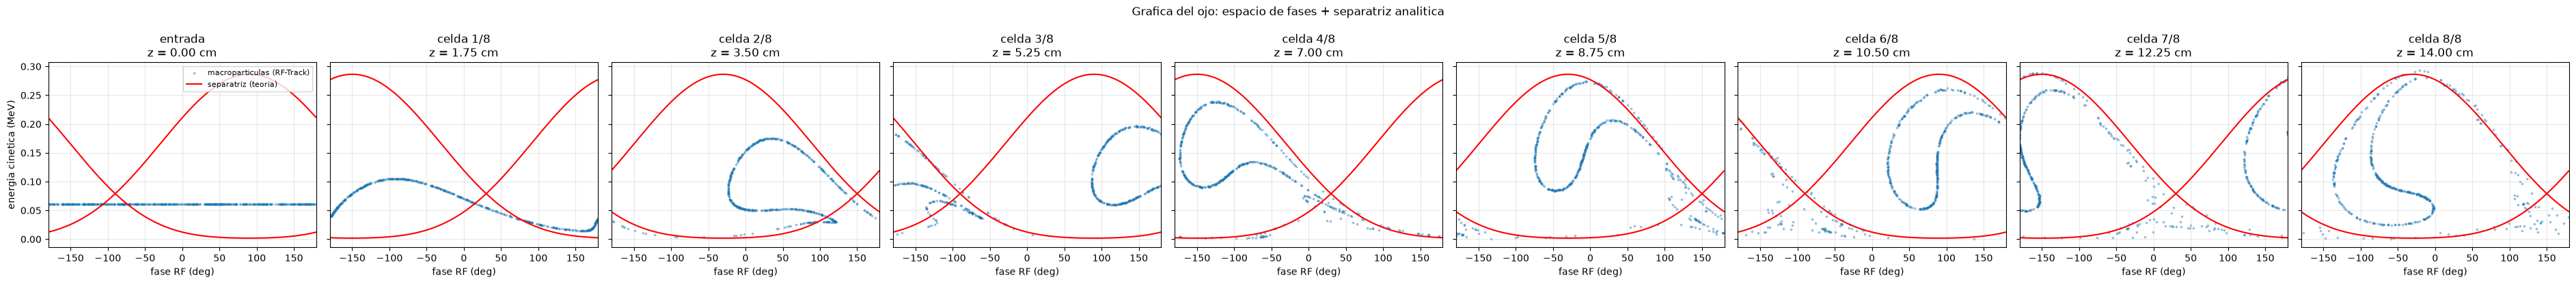

In [4]:
_demo_eye_diagram()